# 📊 Báo Cáo Trực Quan Hóa Dữ Liệu Dân Số Việt Nam
## 🏙️ PHẦN 1: DỮ LIỆU DÂN SỐ TP. HỒ CHÍ MINH (MỚI)
## 🇻🇳 PHẦN 2: TOP 10 TỈNH ĐÔNG DÂN NHẤT VIỆT NAM (THEO DỮ LIỆU MỚI CỦA TP.HCM)

**Nguồn tham chiếu dữ liệu:** 
- [danso.info/dan-so-tp-hcm-moi/](https://danso.info/dan-so-tp-hcm-moi/): Dân số TP.HCM mới sau phương án sáp nhập tỉnh (TP.HCM + Bình Dương + Bà Rịa - Vũng Tàu).
- [danso.info/top-10-tinh-dong-dan-nhat-viet-nam/](https://danso.info/top-10-tinh-dong-dan-nhat-viet-nam/) & [danso.info/top-10-tinh-co-dan-so-dong-nhat-sau-sap-nhap/](https://danso.info/top-10-tinh-co-dan-so-dong-nhat-sau-sap-nhap/): Bảng xếp hạng các địa phương đông dân nhất.

---
### 📌 Cấu trúc nghiên cứu:
* **Phần 1: Trực quan hóa chuyên sâu dữ liệu Dân số TP. Hồ Chí Minh (Mới)**
  1. Cấu phần 3 tỉnh/thành sáp nhập tạo nên siêu đô thị TP.HCM mới (13,57 triệu dân).
  2. Diễn biến quy mô dân số TP.HCM mới trong 10 năm qua (2015 – 2024).
  3. Xu hướng tốc độ tăng trưởng hàng năm (%) và phân tích tác động của dịch COVID-19 (2021).
  4. Cơ cấu các dân tộc sinh sống tại TP.HCM mới và mức độ tập trung so với toàn quốc.
* **Phần 2: Trực quan hóa dữ liệu Top 10 tỉnh đông dân nhất Việt Nam theo dữ liệu mới của TP.HCM**
  1. Bảng xếp hạng Top 10 mới (với TP.HCM mới đạt 13,57M, Bình Dương hợp nhất vào TP.HCM).
  2. So sánh đối đầu quy mô dân số: TP.HCM cũ vs TP.HCM mới trong Top 10 cả nước.
  3. Tỷ trọng dân số Top 10 mới so với toàn quốc (Donut chart).
  4. Tương quan 3 chiều giữa Dân số, Diện tích và Mật độ dân cư theo dữ liệu mới (Bubble chart).
  5. Mở rộng: Bức tranh Top 10 tỉnh/thành đông dân nhất toàn quốc theo phương án 34 tỉnh/thành sau sáp nhập.


In [2]:
# Cài đặt và thiết lập môi trường phân tích dữ liệu
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

try:
    import seaborn as sns
    plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
except ImportError:
    plt.style.use('ggplot' if 'ggplot' in plt.style.available else 'default')

# Thiết lập font hiển thị tiếng Việt hoàn chỉnh
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Liberation Sans', 'Noto Sans', 'Arial']
plt.rcParams['axes.unicode_minus'] = False

# Định dạng hiển thị số thực trong pandas
pd.set_option('display.float_format', lambda x: '%.2f' % x)

print("✅ Môi trường phân tích và hiển thị đã sẵn sàng!")


✅ Môi trường phân tích và hiển thị đã sẵn sàng!


In [3]:
# Đọc các tập dữ liệu đã chuẩn hóa từ thư mục data/
df_sapnhap = pd.read_csv('data/tphcm_moi_thanh_phan_sap_nhap.csv')
df_tphcm_10y = pd.read_csv('data/dan_so_tphcm_moi_10_nam.csv')
df_dantoc = pd.read_csv('data/tphcm_moi_co_cau_dan_toc.csv')
df_top10_new = pd.read_csv('data/top_10_theo_du_lieu_tphcm_moi.csv')
df_top10_34 = pd.read_csv('data/top_10_sau_sap_nhap_34_tinh.csv')

print("✅ Đã nạp thành công 5 tập dữ liệu dân số!")


✅ Đã nạp thành công 5 tập dữ liệu dân số!


---
# 🏙️ PHẦN 1: TRỰC QUAN HÓA DỮ LIỆU DÂN SỐ TP. HỒ CHÍ MINH (MỚI)
*(Dữ liệu từ bài viết: https://danso.info/dan-so-tp-hcm-moi/)*

Theo đề án định hướng quy hoạch và liên kết vùng Đông Nam Bộ, **TP. Hồ Chí Minh mới** được dự phóng dựa trên sự hợp nhất sức mạnh của 3 trọng điểm kinh tế:
* **TP. Hồ Chí Minh (cũ):** 9.521.886 người (đóng góp **70,15%**)
* **Bình Dương (cũ):** 2.858.815 người (đóng góp **21,06%**)
* **Bà Rịa - Vũng Tàu (cũ):** 1.192.863 người (đóng góp **8,79%**)
➡️ **Tổng dân số TP.HCM mới là 13.573.564 người**, đứng vị trí **1/34** đơn vị hành chính sau sáp nhập, chiếm **13,42%** dân số cả nước, diện tích đạt **6.773 km²**, mật độ bình quân **2.004 người/km²**.


In [5]:
# Bảng tổng hợp các thành phần sáp nhập tạo nên TP.HCM mới
print("=== CÁC THÀNH PHẦN HỢP NHẤT TẠO NÊN TP. HỒ CHÍ MINH MỚI ===")
df_sapnhap


=== CÁC THÀNH PHẦN HỢP NHẤT TẠO NÊN TP. HỒ CHÍ MINH MỚI ===


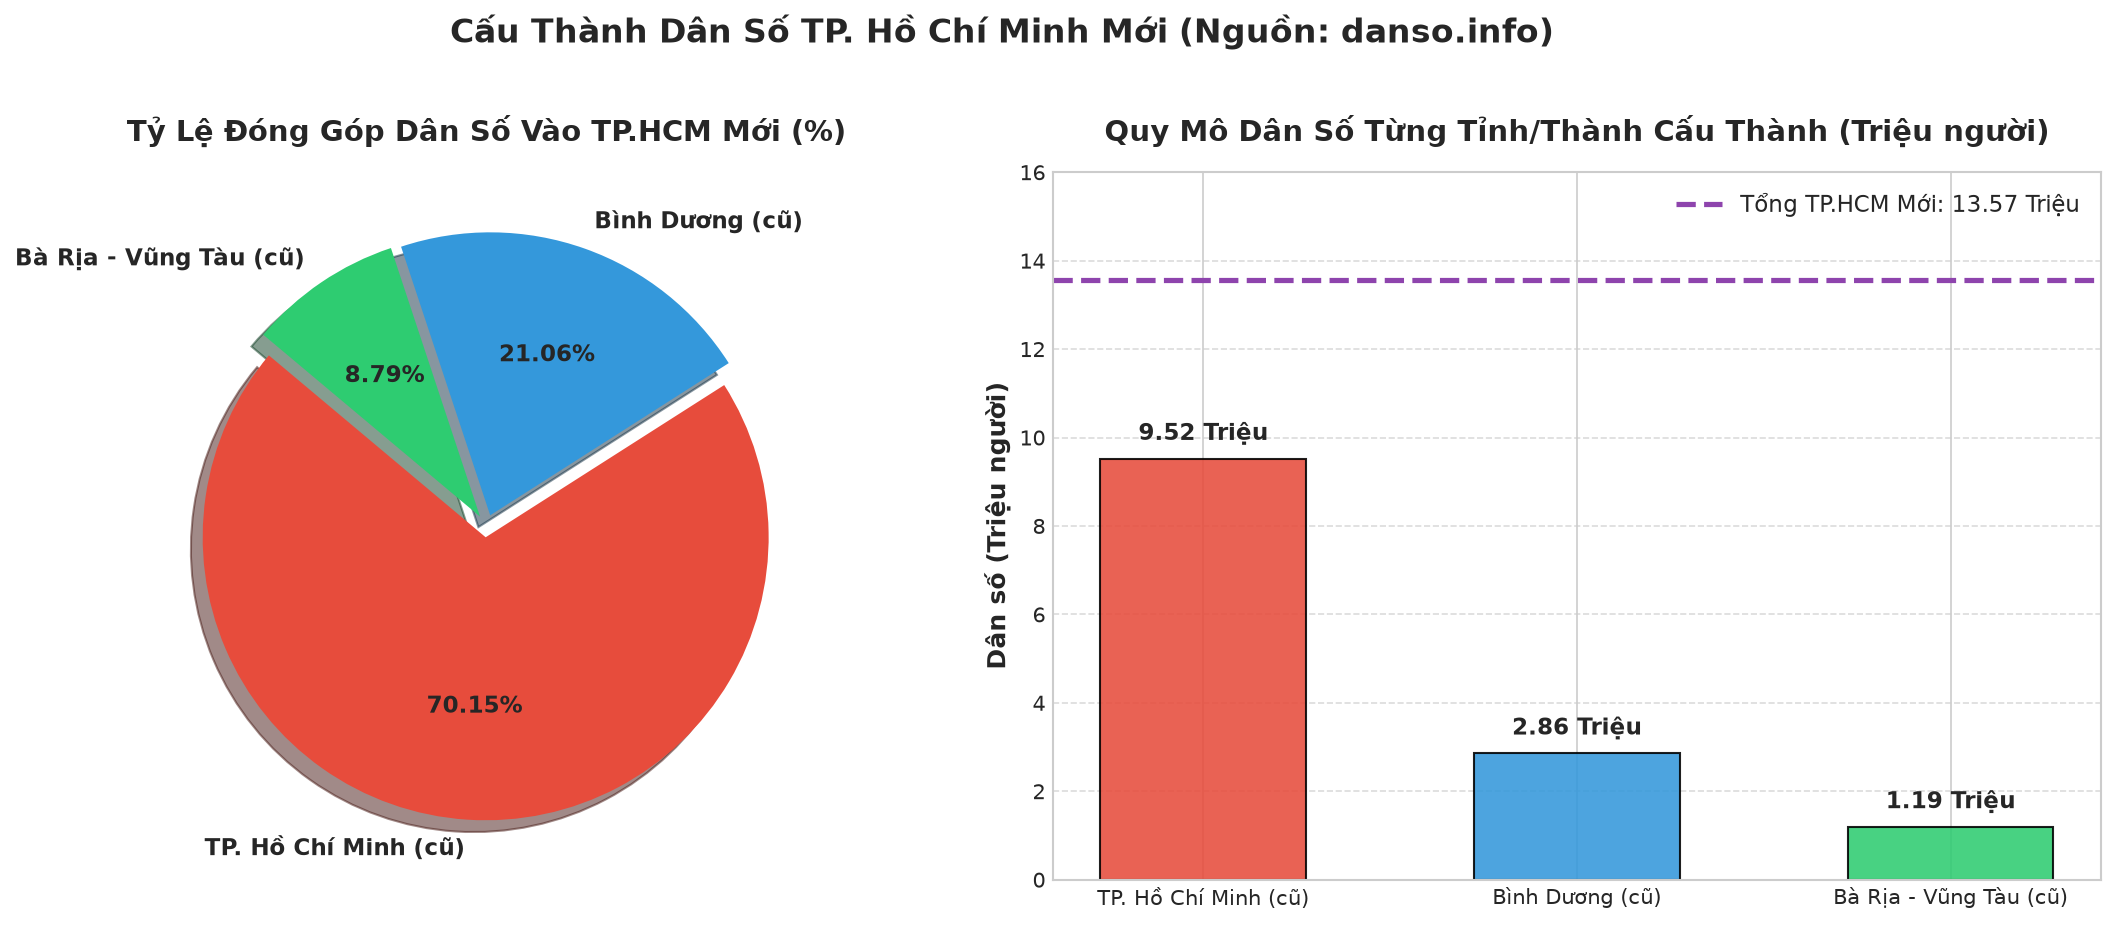

In [6]:
# 1. Trực quan hóa cấu phần hợp nhất tạo nên TP.HCM mới
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

colors = ['#e74c3c', '#3498db', '#2ecc71']

# Pie chart: Tỷ lệ % đóng góp
wedges, texts, autotexts = ax1.pie(
    df_sapnhap['Share_pct'], labels=df_sapnhap['Component'], autopct='%1.2f%%',
    startangle=140, colors=colors, explode=(0.04, 0.04, 0.04),
    shadow=True, textprops={'fontsize': 11, 'fontweight': 'bold'}
)
ax1.set_title('Tỷ Lệ Đóng Góp Dân Số Vào TP.HCM Mới (%)', fontsize=14, fontweight='bold', pad=15)

# Bar chart: Quy mô dân số từng địa phương và tổng TP.HCM mới
bars = ax2.bar(df_sapnhap['Component'], df_sapnhap['Population'] / 1e6, color=colors, edgecolor='black', alpha=0.88, width=0.55)
ax2.set_title('Quy Mô Dân Số Từng Tỉnh/Thành Cấu Thành (Triệu người)', fontsize=14, fontweight='bold', pad=15)
ax2.set_ylabel('Dân số (Triệu người)', fontsize=12, fontweight='bold')
ax2.set_ylim(0, 16)
ax2.grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars:
    y = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, y + 0.3, f'{y:.2f} Triệu', ha='center', va='bottom', fontweight='bold', fontsize=11)

# Đường tổng dân số TP.HCM mới
total_pop = df_sapnhap['Population'].sum() / 1e6
ax2.axhline(total_pop, color='#8e44ad', linestyle='--', linewidth=2.5, label=f'Tổng TP.HCM Mới: {total_pop:.2f} Triệu')
ax2.legend(loc='upper right', fontsize=11)

plt.suptitle('Cấu Thành Dân Số TP. Hồ Chí Minh Mới (Nguồn: danso.info)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


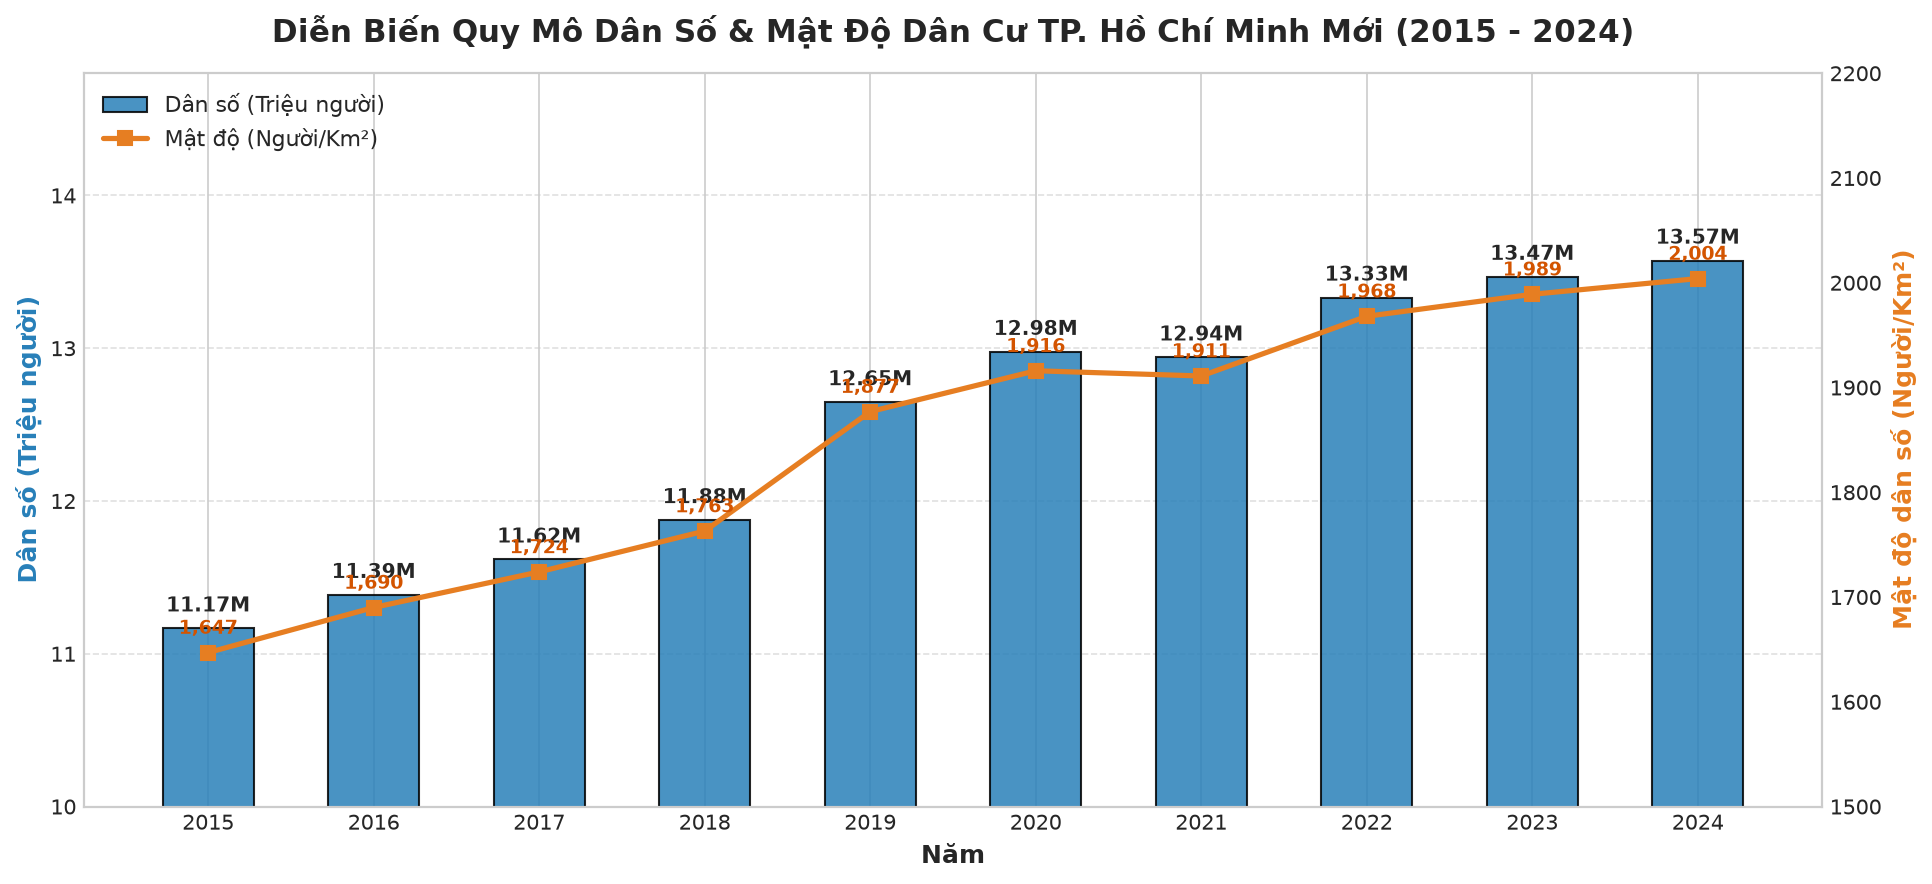

In [7]:
# 2. Diễn biến quy mô dân số và mật độ dân số TP.HCM mới 10 năm (2015 – 2024)
fig, ax1 = plt.subplots(figsize=(13, 6))

years = df_tphcm_10y['Year']
pop = df_tphcm_10y['Population'] / 1e6
density = df_tphcm_10y['Density_per_km2']

# Cột quy mô dân số
bars = ax1.bar(years, pop, color='#2980b9', alpha=0.85, edgecolor='black', width=0.55, label='Dân số (Triệu người)')
ax1.set_xlabel('Năm', fontsize=12, fontweight='bold')
ax1.set_ylabel('Dân số (Triệu người)', fontsize=12, fontweight='bold', color='#2980b9')
ax1.set_xticks(years)
ax1.set_ylim(10, 14.8)
ax1.grid(axis='y', linestyle='--', alpha=0.6)

for bar in bars:
    y = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, y + 0.08, f'{y:.2f}M', ha='center', va='bottom', fontsize=9.5, fontweight='bold')

# Đường mật độ dân số
ax2 = ax1.twinx()
ax2.plot(years, density, color='#e67e22', marker='s', linewidth=2.5, markersize=7, label='Mật độ (Người/Km²)')
ax2.set_ylabel('Mật độ dân số (Người/Km²)', fontsize=12, fontweight='bold', color='#e67e22')
ax2.set_ylim(1500, 2200)
ax2.grid(False)

for x, y in zip(years, density):
    ax2.annotate(f'{y:,}', (x, y), textcoords="offset points", xytext=(0, 9), ha='center', fontsize=9, fontweight='bold', color='#d35400')

# Gộp chú thích
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=10.5)

plt.title('Diễn Biến Quy Mô Dân Số & Mật Độ Dân Cư TP. Hồ Chí Minh Mới (2015 - 2024)', fontsize=15, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


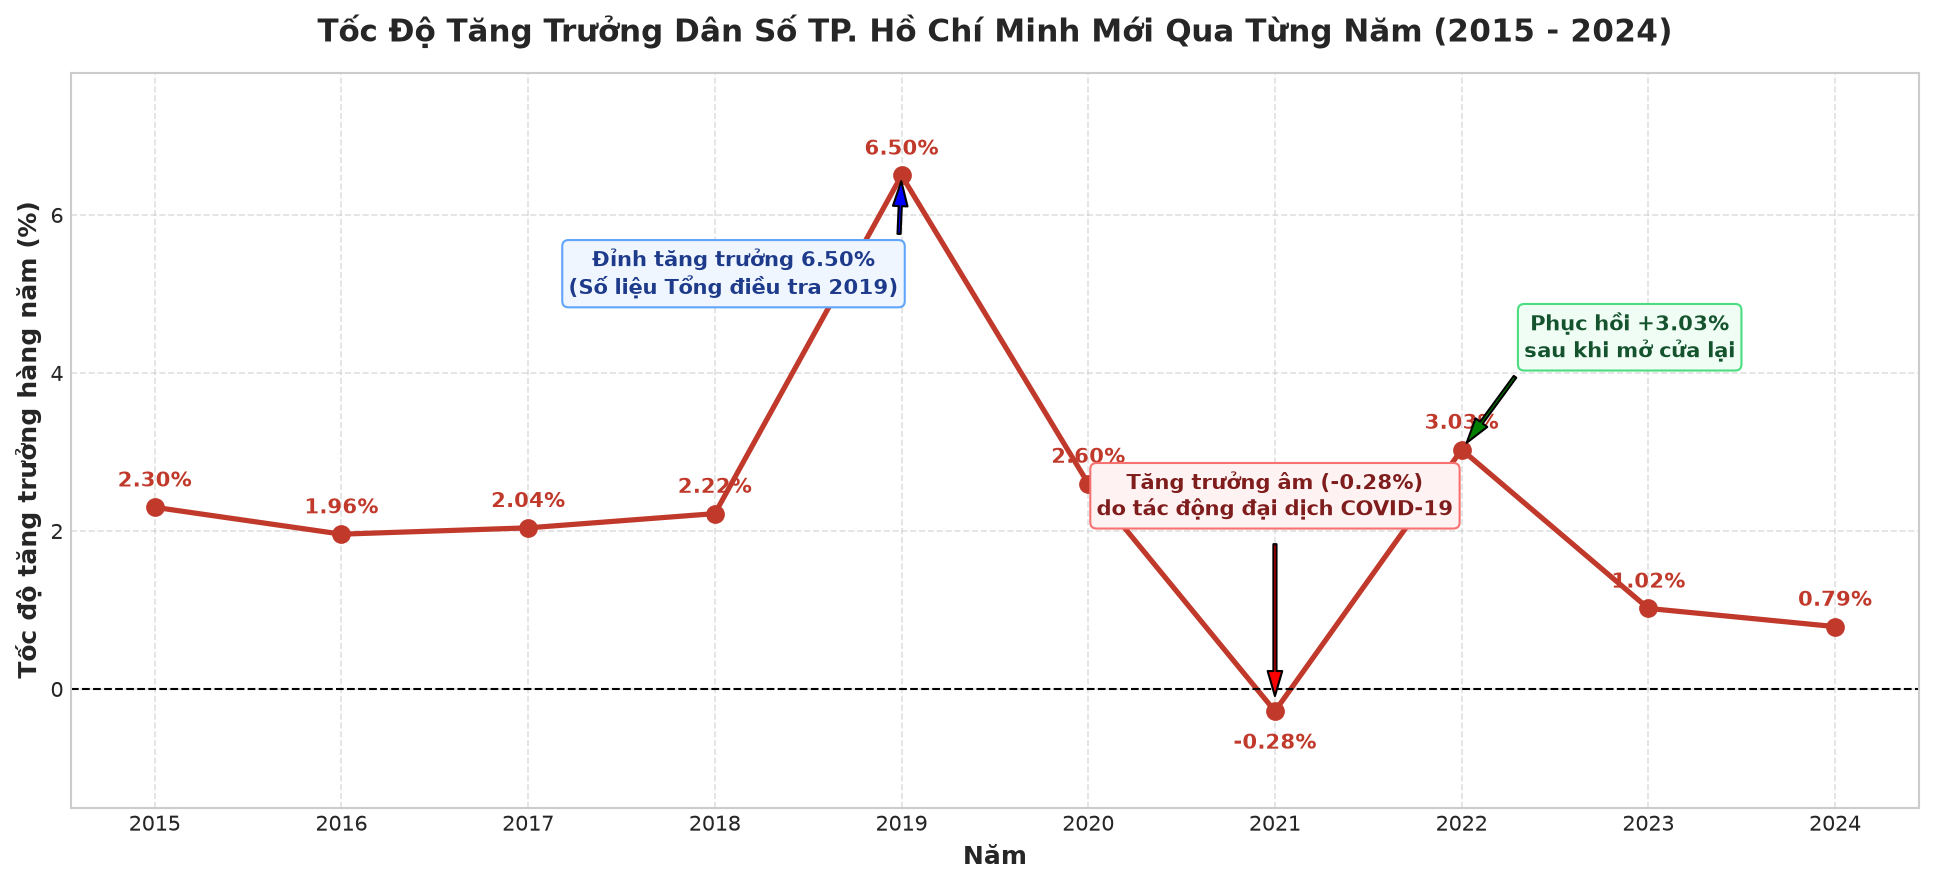

In [8]:
# 3. Tốc độ tăng trưởng dân số hàng năm (%) và phân tích biến cố COVID-19
fig, ax = plt.subplots(figsize=(13, 6))

growth = df_tphcm_10y['Growth_Rate_pct']
line = ax.plot(years, growth, color='#c0392b', marker='o', linewidth=2.5, markersize=8)

ax.set_title('Tốc Độ Tăng Trưởng Dân Số TP. Hồ Chí Minh Mới Qua Từng Năm (2015 - 2024)', fontsize=15, fontweight='bold', pad=15)
ax.set_xlabel('Năm', fontsize=12, fontweight='bold')
ax.set_ylabel('Tốc độ tăng trưởng hàng năm (%)', fontsize=12, fontweight='bold')
ax.set_xticks(years)
ax.set_ylim(-1.5, 7.8)
ax.axhline(0, color='black', linestyle='--', linewidth=1)
ax.grid(True, linestyle='--', alpha=0.6)

for x, y in zip(years, growth):
    ax.annotate(f'{y:.2f}%', (x, y), textcoords="offset points", xytext=(0, 10 if y >= 0 else -18),
                ha='center', fontsize=10, fontweight='bold', color='#c0392b')

# Ghi chú mốc 2019 (Tổng điều tra)
ax.annotate('Đỉnh tăng trưởng 6.50%\n(Số liệu Tổng điều tra 2019)', 
            xy=(2019, 6.50), xytext=(2018.1, 5.0),
            arrowprops=dict(facecolor='blue', shrink=0.08, width=1.5, headwidth=7),
            ha='center', fontsize=10, fontweight='bold', color='#1e3a8a',
            bbox=dict(boxstyle="round,pad=0.3", fc="#eff6ff", ec="#60a5fa"))

# Ghi chú mốc 2021 (Đại dịch COVID-19)
ax.annotate('Tăng trưởng âm (-0.28%)\ndo tác động đại dịch COVID-19', 
            xy=(2021, -0.28), xytext=(2021, 2.2),
            arrowprops=dict(facecolor='red', shrink=0.08, width=1.5, headwidth=7),
            ha='center', fontsize=10, fontweight='bold', color='#7f1d1d',
            bbox=dict(boxstyle="round,pad=0.3", fc="#fef2f2", ec="#f87171"))

# Ghi chú mốc 2022 (Phục hồi hậu dịch)
ax.annotate('Phục hồi +3.03%\nsau khi mở cửa lại', 
            xy=(2022, 3.03), xytext=(2022.9, 4.2),
            arrowprops=dict(facecolor='green', shrink=0.08, width=1.5, headwidth=7),
            ha='center', fontsize=10, fontweight='bold', color='#14532d',
            bbox=dict(boxstyle="round,pad=0.3", fc="#f0fdf4", ec="#4ade80"))

plt.tight_layout()
plt.show()


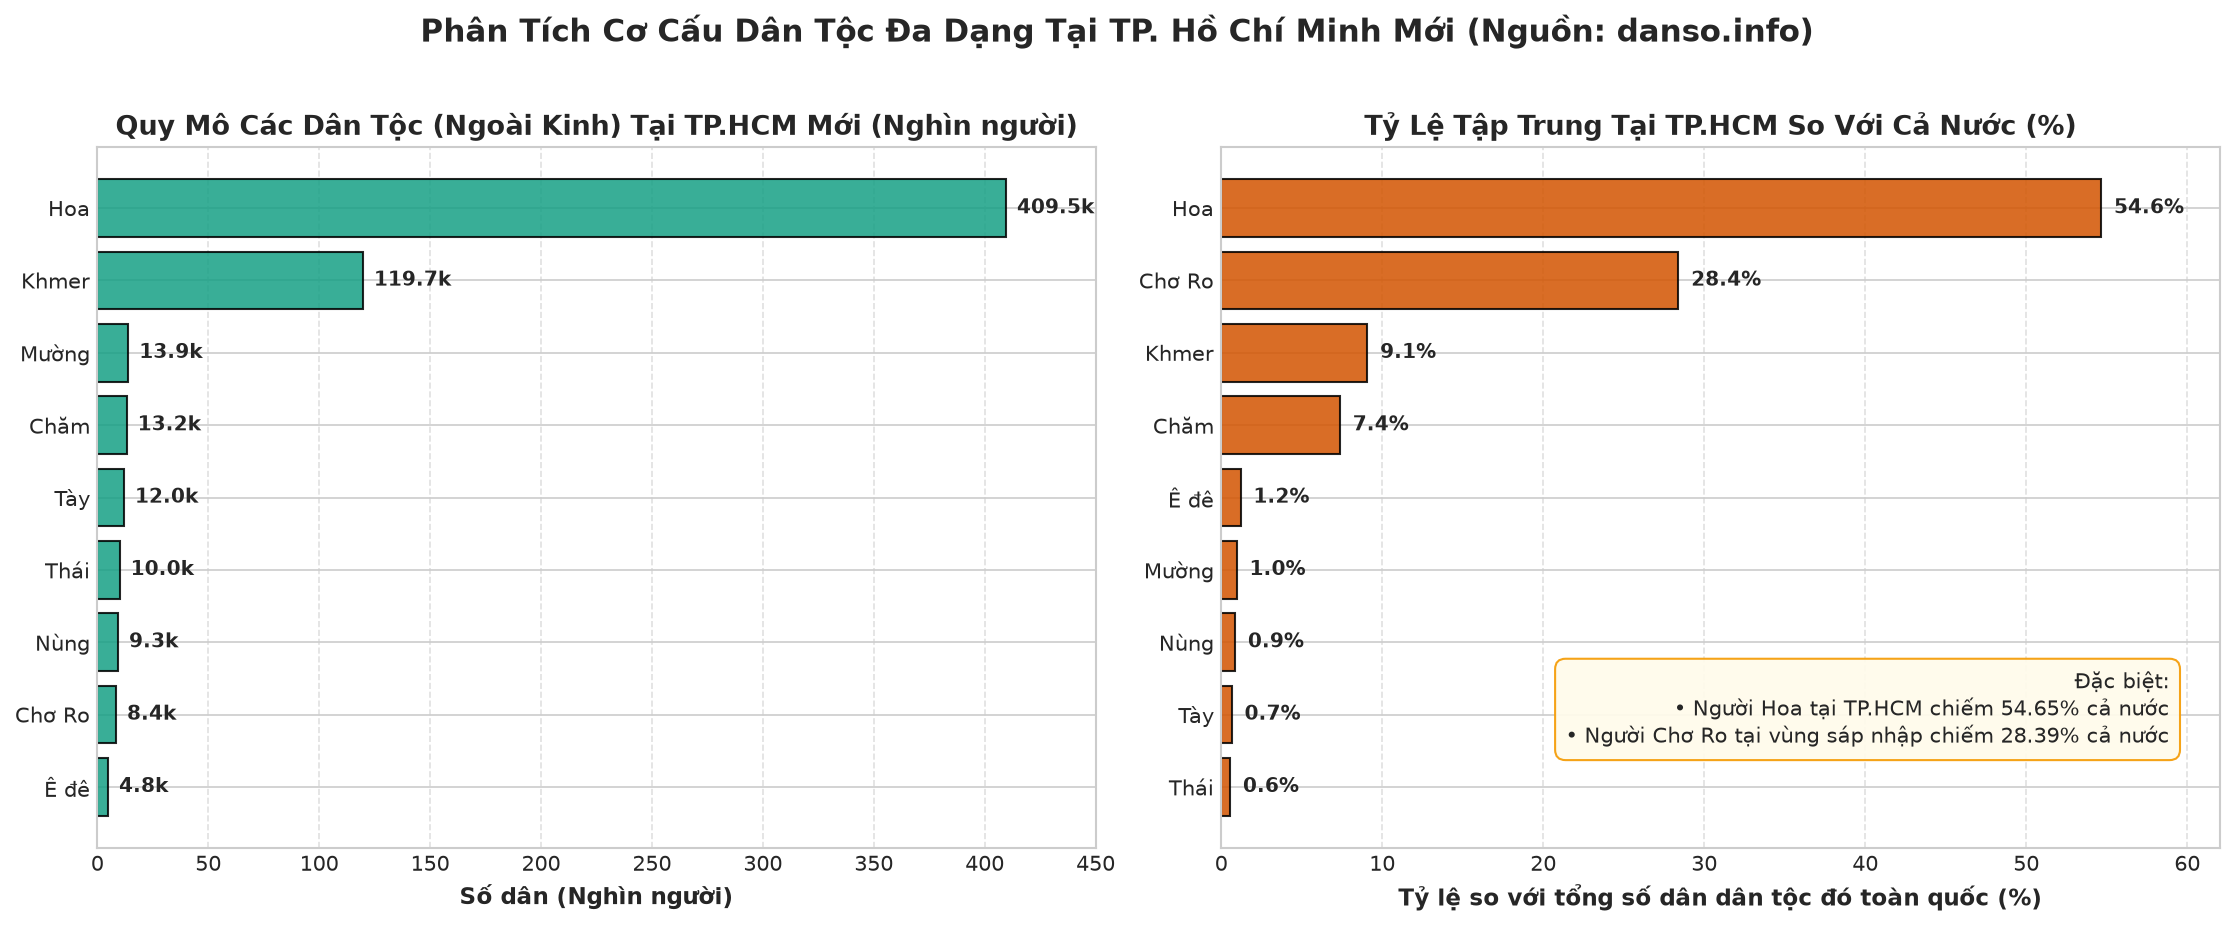

In [9]:
# 4. Cơ cấu dân tộc đa dạng tại TP. Hồ Chí Minh Mới
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

df_minority = df_dantoc[~df_dantoc['Ethnicity'].isin(['Kinh', 'Các dân tộc khác'])].sort_values(by='Population_TPHCM', ascending=True)

# Biểu đồ 1: Số dân các dân tộc (trừ dân tộc Kinh chiếm 95.11%)
bars1 = ax1.barh(df_minority['Ethnicity'], df_minority['Population_TPHCM'] / 1e3, color='#16a085', edgecolor='black', alpha=0.85)
ax1.set_title('Quy Mô Các Dân Tộc (Ngoài Kinh) Tại TP.HCM Mới (Nghìn người)', fontsize=13, fontweight='bold')
ax1.set_xlabel('Số dân (Nghìn người)', fontsize=11, fontweight='bold')
ax1.set_xlim(0, 450)
ax1.grid(axis='x', linestyle='--', alpha=0.6)

for bar in bars1:
    w = bar.get_width()
    ax1.text(w + 5, bar.get_y() + bar.get_height()/2, f'{w:.1f}k', va='center', ha='left', fontsize=9.5, fontweight='bold')

# Biểu đồ 2: Tỷ lệ tập trung dân tộc đó tại TP.HCM so với cả nước (%)
df_concentrate = df_minority.sort_values(by='Share_National_pct', ascending=True)
bars2 = ax2.barh(df_concentrate['Ethnicity'], df_concentrate['Share_National_pct'], color='#d35400', edgecolor='black', alpha=0.85)
ax2.set_title('Tỷ Lệ Tập Trung Tại TP.HCM So Với Cả Nước (%)', fontsize=13, fontweight='bold')
ax2.set_xlabel('Tỷ lệ so với tổng số dân dân tộc đó toàn quốc (%)', fontsize=11, fontweight='bold')
ax2.set_xlim(0, 62)
ax2.grid(axis='x', linestyle='--', alpha=0.6)

for bar in bars2:
    w = bar.get_width()
    ax2.text(w + 0.8, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center', ha='left', fontsize=9.5, fontweight='bold')

# Chú thích
ax2.text(0.95, 0.15, 'Đặc biệt:\n• Người Hoa tại TP.HCM chiếm 54.65% cả nước\n• Người Chơ Ro tại vùng sáp nhập chiếm 28.39% cả nước', 
         transform=ax2.transAxes, ha='right', fontsize=10, 
         bbox=dict(boxstyle='round,pad=0.5', facecolor='#fffbeb', edgecolor='#f59e0b', alpha=0.95))

plt.suptitle('Phân Tích Cơ Cấu Dân Tộc Đa Dạng Tại TP. Hồ Chí Minh Mới (Nguồn: danso.info)', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


---
# 🇻🇳 PHẦN 2: TRỰC QUAN HÓA TOP 10 TỈNH ĐÔNG DÂN NHẤT VIỆT NAM (THEO DỮ LIỆU MỚI CỦA TP.HCM)

Khi cập nhật dữ liệu mới của **TP. Hồ Chí Minh** (13.573.564 người sau khi sáp nhập Bình Dương và Bà Rịa - Vũng Tàu):
1. **TP. Hồ Chí Minh (Mới)** giữ vững vị trí **Số 1**, chiếm **13,42%** dân số cả nước, bỏ xa Thủ đô Hà Nội ở vị trí số 2 (8,69 triệu người).
2. Vì **Bình Dương** (trước đây đứng hạng 6) và **Bà Rịa - Vũng Tàu** đã chính thức nằm trong TP.HCM mới, các địa phương phía sau được đôn lên thứ hạng cao hơn. Tỉnh **An Giang** (với 1,91 triệu dân) bước vào Top 10 cả nước.
3. Top 10 mới đóng góp đến **43,1%** tổng dân số toàn quốc.


In [ ]:
# Bảng xếp hạng Top 10 Tỉnh/Thành đông dân nhất theo dữ liệu mới của TP.HCM
print("=== BẢNG XẾP HẠNG TOP 10 THEO DỮ LIỆU MỚI CỦA TP.HCM ===")
df_top10_new[['Rank', 'Province', 'Region', 'Population', 'Area_km2', 'Density_per_km2', 'Population_Share_pct', 'Note']]


=== BẢNG XẾP HẠNG TOP 10 THEO DỮ LIỆU MỚI CỦA TP.HCM ===


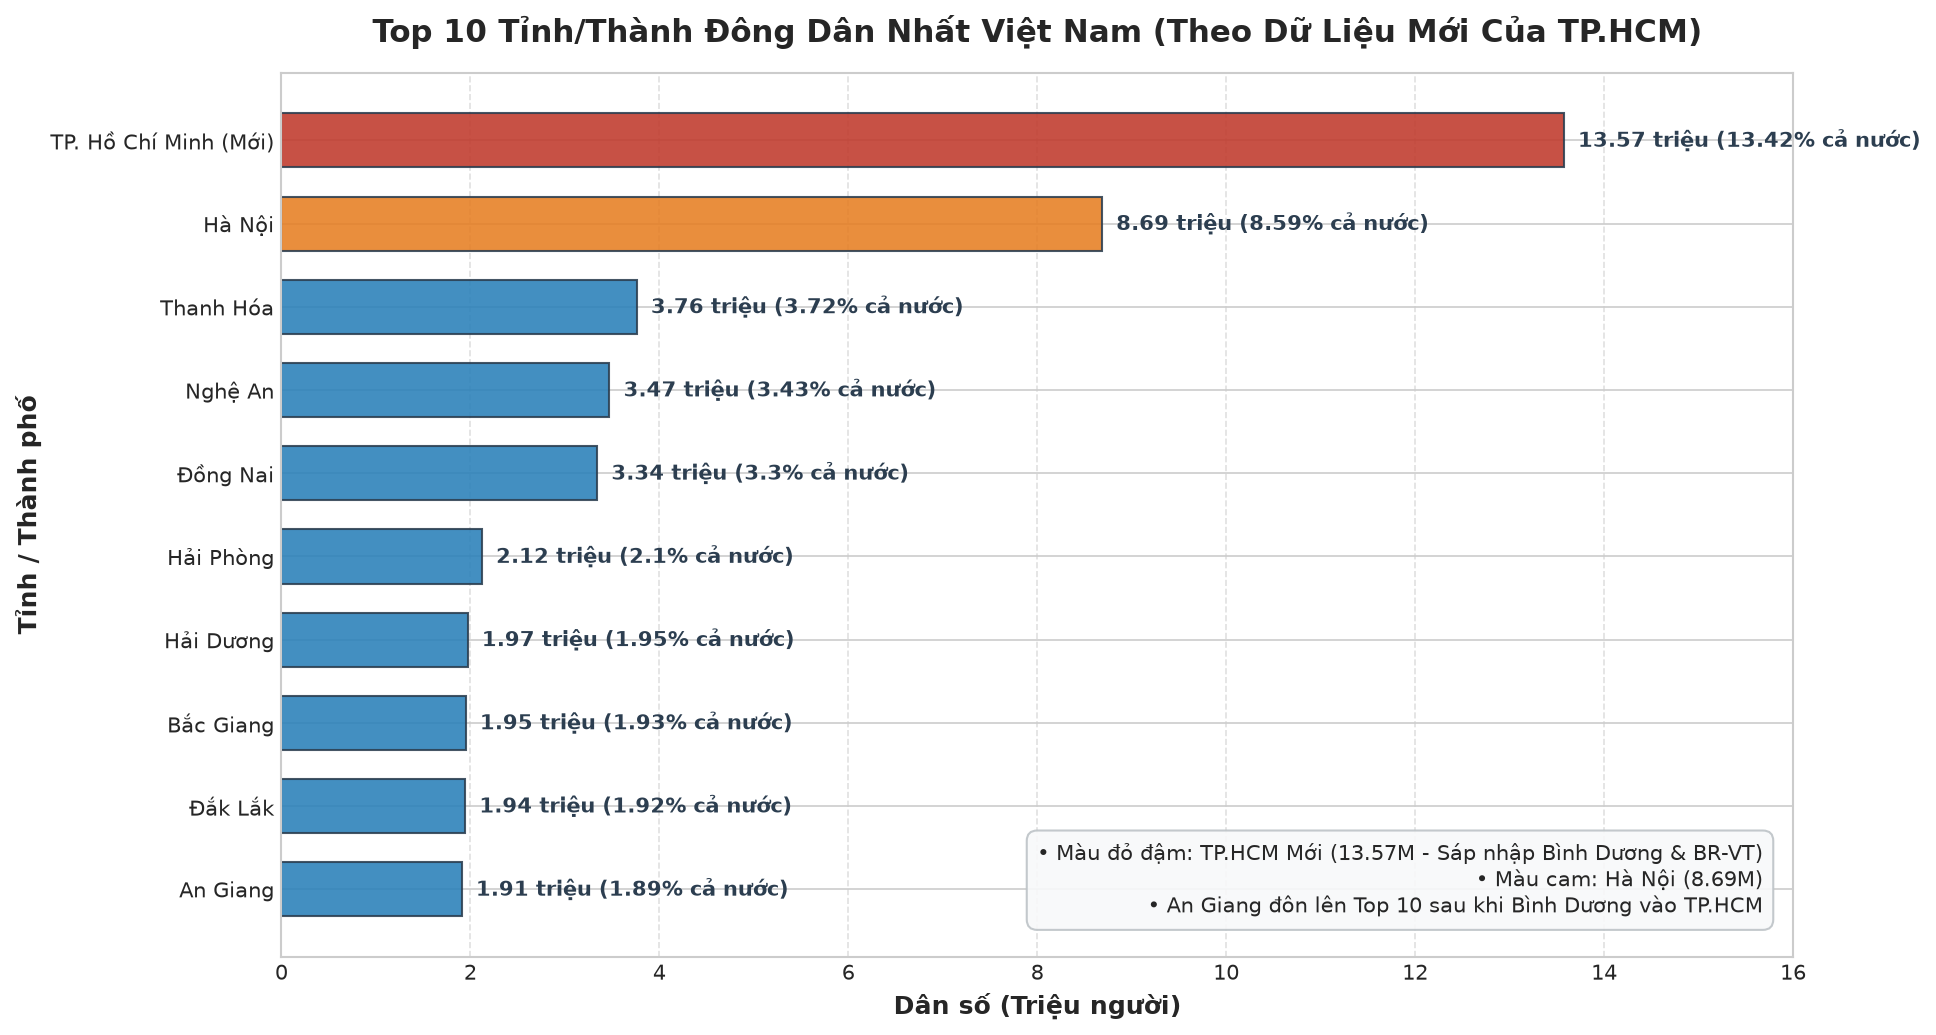

In [12]:
# 5. Biểu đồ thanh ngang: Top 10 tỉnh đông dân nhất VN theo dữ liệu mới của TP.HCM
fig, ax = plt.subplots(figsize=(13, 7))

df_sorted_new = df_top10_new.sort_values(by='Population', ascending=True).reset_index(drop=True)

# Bảng màu: Đỏ đậm cho TP.HCM mới, Cam cho Hà Nội, Xanh cho các tỉnh còn lại
colors = ['#c0392b' if 'TP. Hồ Chí Minh' in p else ('#e67e22' if 'Hà Nội' in p else '#2980b9') for p in df_sorted_new['Province']]

bars = ax.barh(df_sorted_new['Province'], df_sorted_new['Population'] / 1e6, color=colors, edgecolor='#2c3e50', alpha=0.88, height=0.65)

for i, bar in enumerate(bars):
    width = bar.get_width()
    share_pct = df_sorted_new.loc[i, 'Population_Share_pct']
    ax.text(width + 0.15, bar.get_y() + bar.get_height()/2, 
            f'{width:.2f} triệu ({share_pct}% cả nước)', 
            va='center', ha='left', fontsize=10, fontweight='bold', color='#2c3e50')

ax.set_title('Top 10 Tỉnh/Thành Đông Dân Nhất Việt Nam (Theo Dữ Liệu Mới Của TP.HCM)', fontsize=15, fontweight='bold', pad=15)
ax.set_xlabel('Dân số (Triệu người)', fontsize=12, fontweight='bold')
ax.set_ylabel('Tỉnh / Thành phố', fontsize=12, fontweight='bold')
ax.set_xlim(0, 16.0)
ax.grid(axis='x', linestyle='--', alpha=0.6)

# Chú giải
ax.text(0.98, 0.05, '• Màu đỏ đậm: TP.HCM Mới (13.57M - Sáp nhập Bình Dương & BR-VT)\n• Màu cam: Hà Nội (8.69M)\n• An Giang đôn lên Top 10 sau khi Bình Dương vào TP.HCM', 
        transform=ax.transAxes, ha='right', fontsize=10, 
        bbox=dict(boxstyle='round,pad=0.5', facecolor='#f8f9fa', alpha=0.9, edgecolor='#bdc3c7'))

plt.tight_layout()
plt.show()


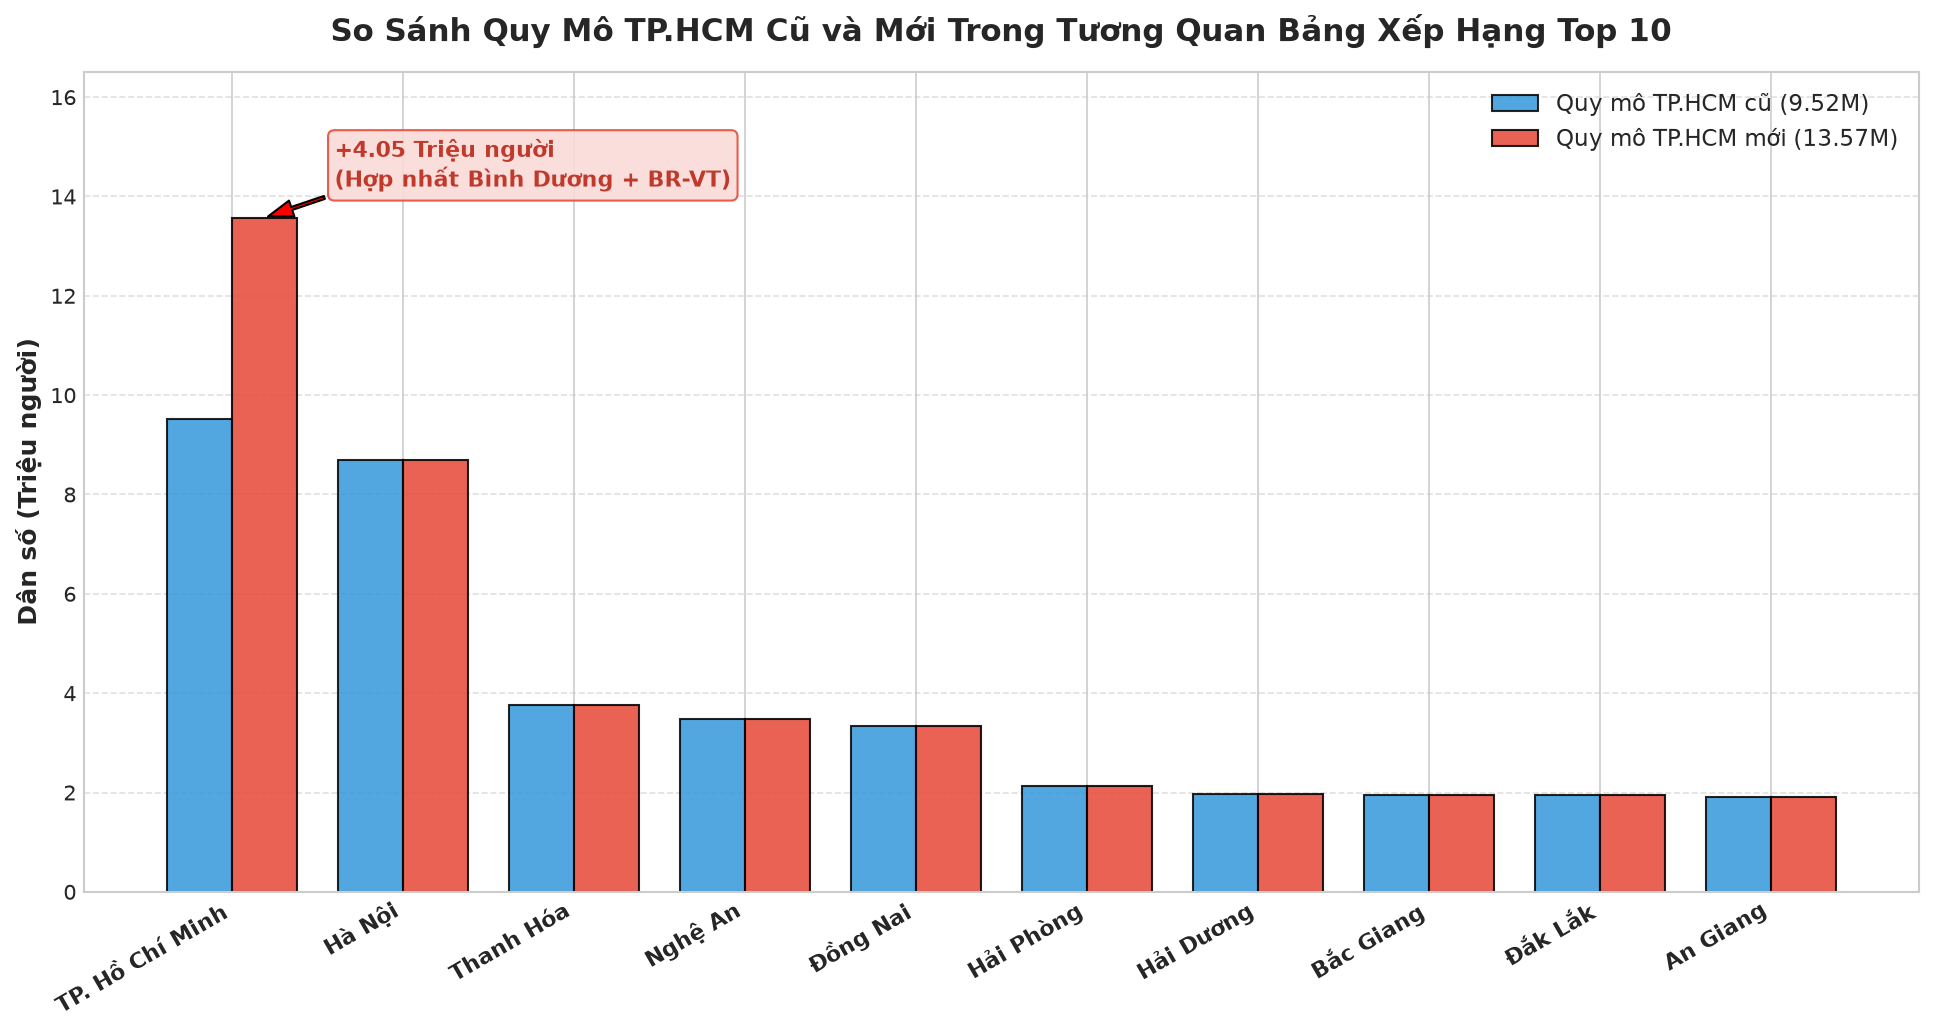

In [13]:
# 6. So sánh quy mô TP.HCM Cũ vs TP.HCM Mới trong bảng xếp hạng
fig, ax = plt.subplots(figsize=(13, 7))

provinces = list(df_top10_new['Province'])
pop_before = [9.521886, 8.685607, 3.760650, 3.470988, 3.341716, 2.121841, 1.971326, 1.950615, 1.944821, 1.908352]
pop_after = list(df_top10_new['Population'] / 1e6)

x = np.arange(len(provinces))
width = 0.38

rects1 = ax.bar(x - width/2, pop_before, width, label='Quy mô TP.HCM cũ (9.52M)', color='#3498db', edgecolor='black', alpha=0.85)
rects2 = ax.bar(x + width/2, pop_after, width, label='Quy mô TP.HCM mới (13.57M)', color='#e74c3c', edgecolor='black', alpha=0.88)

ax.set_title('So Sánh Quy Mô TP.HCM Cũ và Mới Trong Tương Quan Bảng Xếp Hạng Top 10', fontsize=15, fontweight='bold', pad=15)
ax.set_ylabel('Dân số (Triệu người)', fontsize=12, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels([p.replace(' (Mới)', '') for p in provinces], rotation=30, ha='right', fontsize=10.5, fontweight='bold')
ax.set_ylim(0, 16.5)
ax.legend(fontsize=11, loc='upper right')
ax.grid(axis='y', linestyle='--', alpha=0.6)

# Chú thích tăng vọt của TP.HCM mới
ax.annotate('+4.05 Triệu người\n(Hợp nhất Bình Dương + BR-VT)', 
            xy=(0 + width/2, 13.573564), xytext=(0.6, 14.2),
            arrowprops=dict(facecolor='red', shrink=0.05, width=1.5, headwidth=8),
            fontsize=10.5, fontweight='bold', color='#c0392b',
            bbox=dict(boxstyle="round,pad=0.3", fc="#fadbd8", ec="#e74c3c", alpha=0.9))

plt.tight_layout()
plt.show()


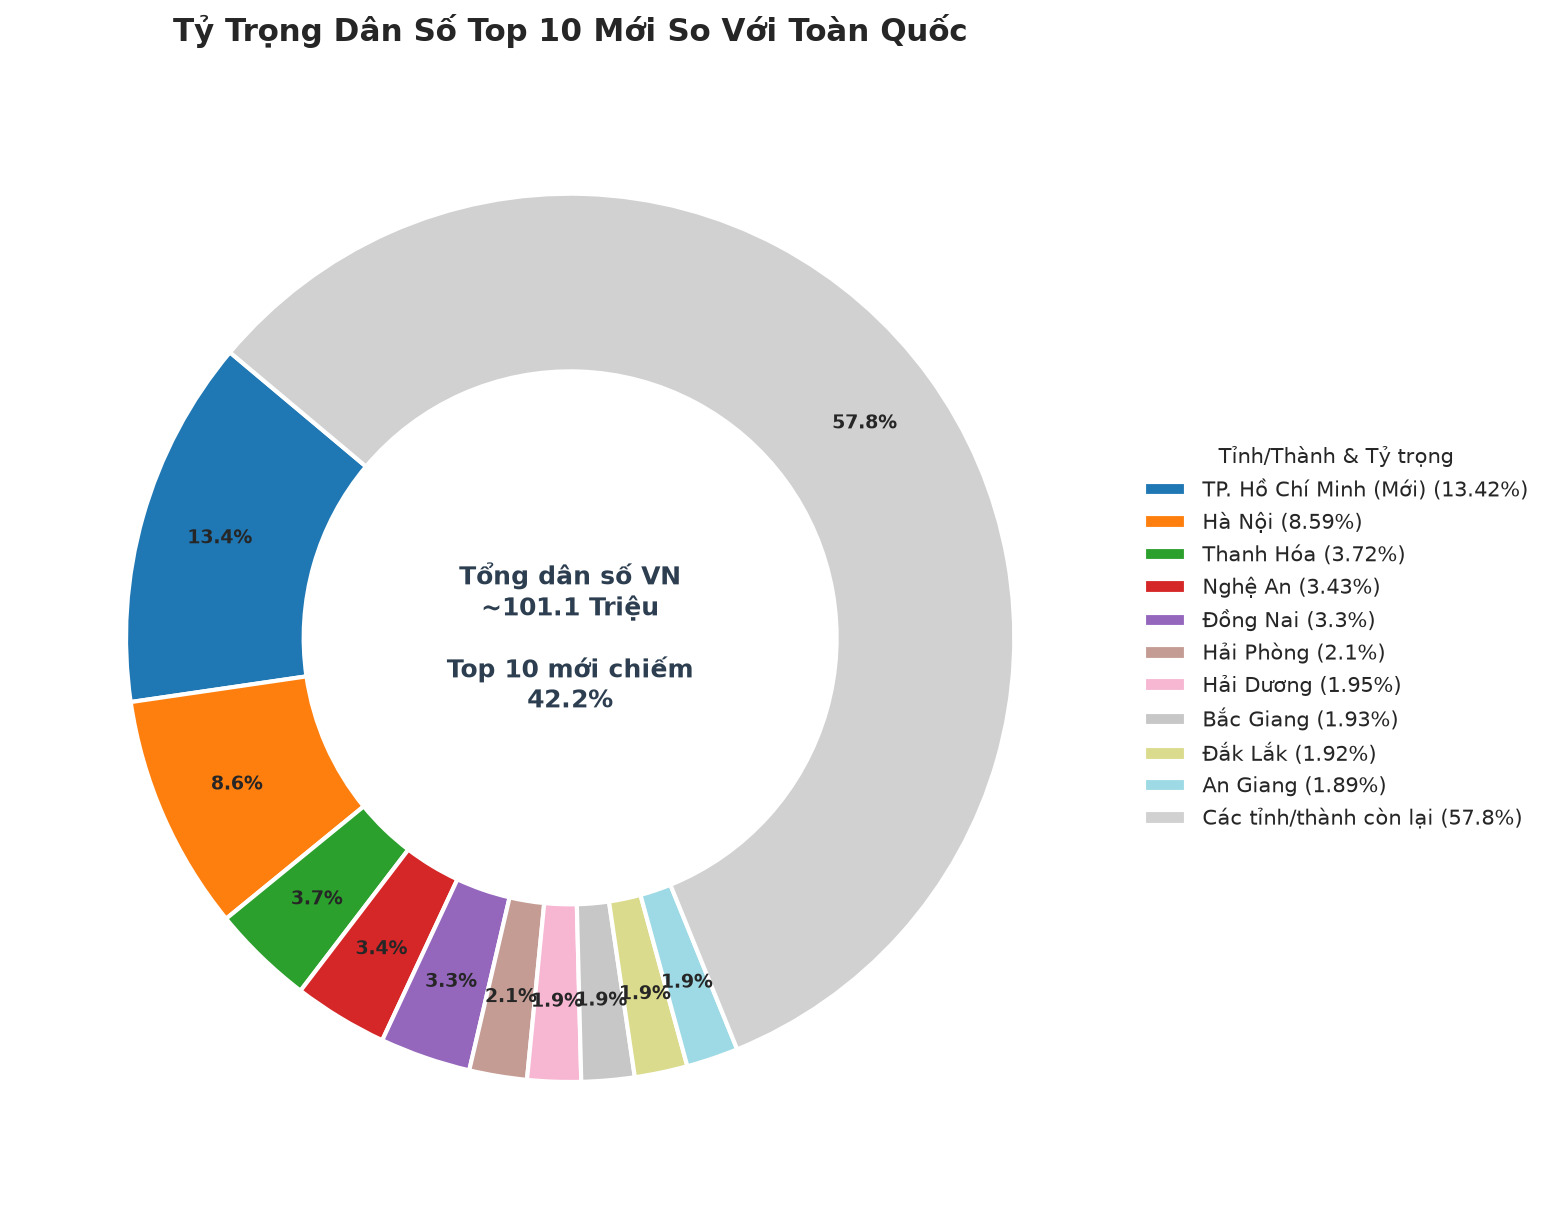

In [14]:
# 7. Biểu đồ tròn (Donut chart): Tỷ trọng dân số Top 10 mới so với toàn quốc
total_vietnam_pop = 101140000 # Ước tính quy mô dân số cả nước
top10_pop = df_top10_new['Population'].sum()
rest_pop = total_vietnam_pop - top10_pop

shares = list(df_top10_new['Population']) + [rest_pop]
labels = [f"{row['Province']} ({row['Population_Share_pct']}%)" for _, row in df_top10_new.iterrows()] + [f"Các tỉnh/thành còn lại ({rest_pop/total_vietnam_pop*100:.1f}%)"]

colors = plt.cm.tab20(np.linspace(0, 1, 10)).tolist() + [(0.82, 0.82, 0.82, 1.0)]

fig, ax = plt.subplots(figsize=(10, 9))
wedges, texts, autotexts = ax.pie(
    shares, 
    labels=None, 
    autopct='%1.1f%%', 
    pctdistance=0.82,
    startangle=140, 
    colors=colors,
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2)
)

for at in autotexts:
    at.set_fontsize(9)
    at.set_weight('bold')

ax.legend(wedges, labels, title="Tỉnh/Thành & Tỷ trọng", loc="center left", bbox_to_anchor=(1, 0, 0.5, 1), fontsize=10)
ax.set_title("Tỷ Trọng Dân Số Top 10 Mới So Với Toàn Quốc", fontsize=15, fontweight='bold', pad=20)

# Chú thích ở giữa vòng tròn
ax.text(0, 0, f"Tổng dân số VN\n~101.1 Triệu\n\nTop 10 mới chiếm\n{top10_pop/total_vietnam_pop*100:.1f}%", 
        ha='center', va='center', fontsize=12, fontweight='bold', color='#2c3e50')

plt.tight_layout()
plt.show()


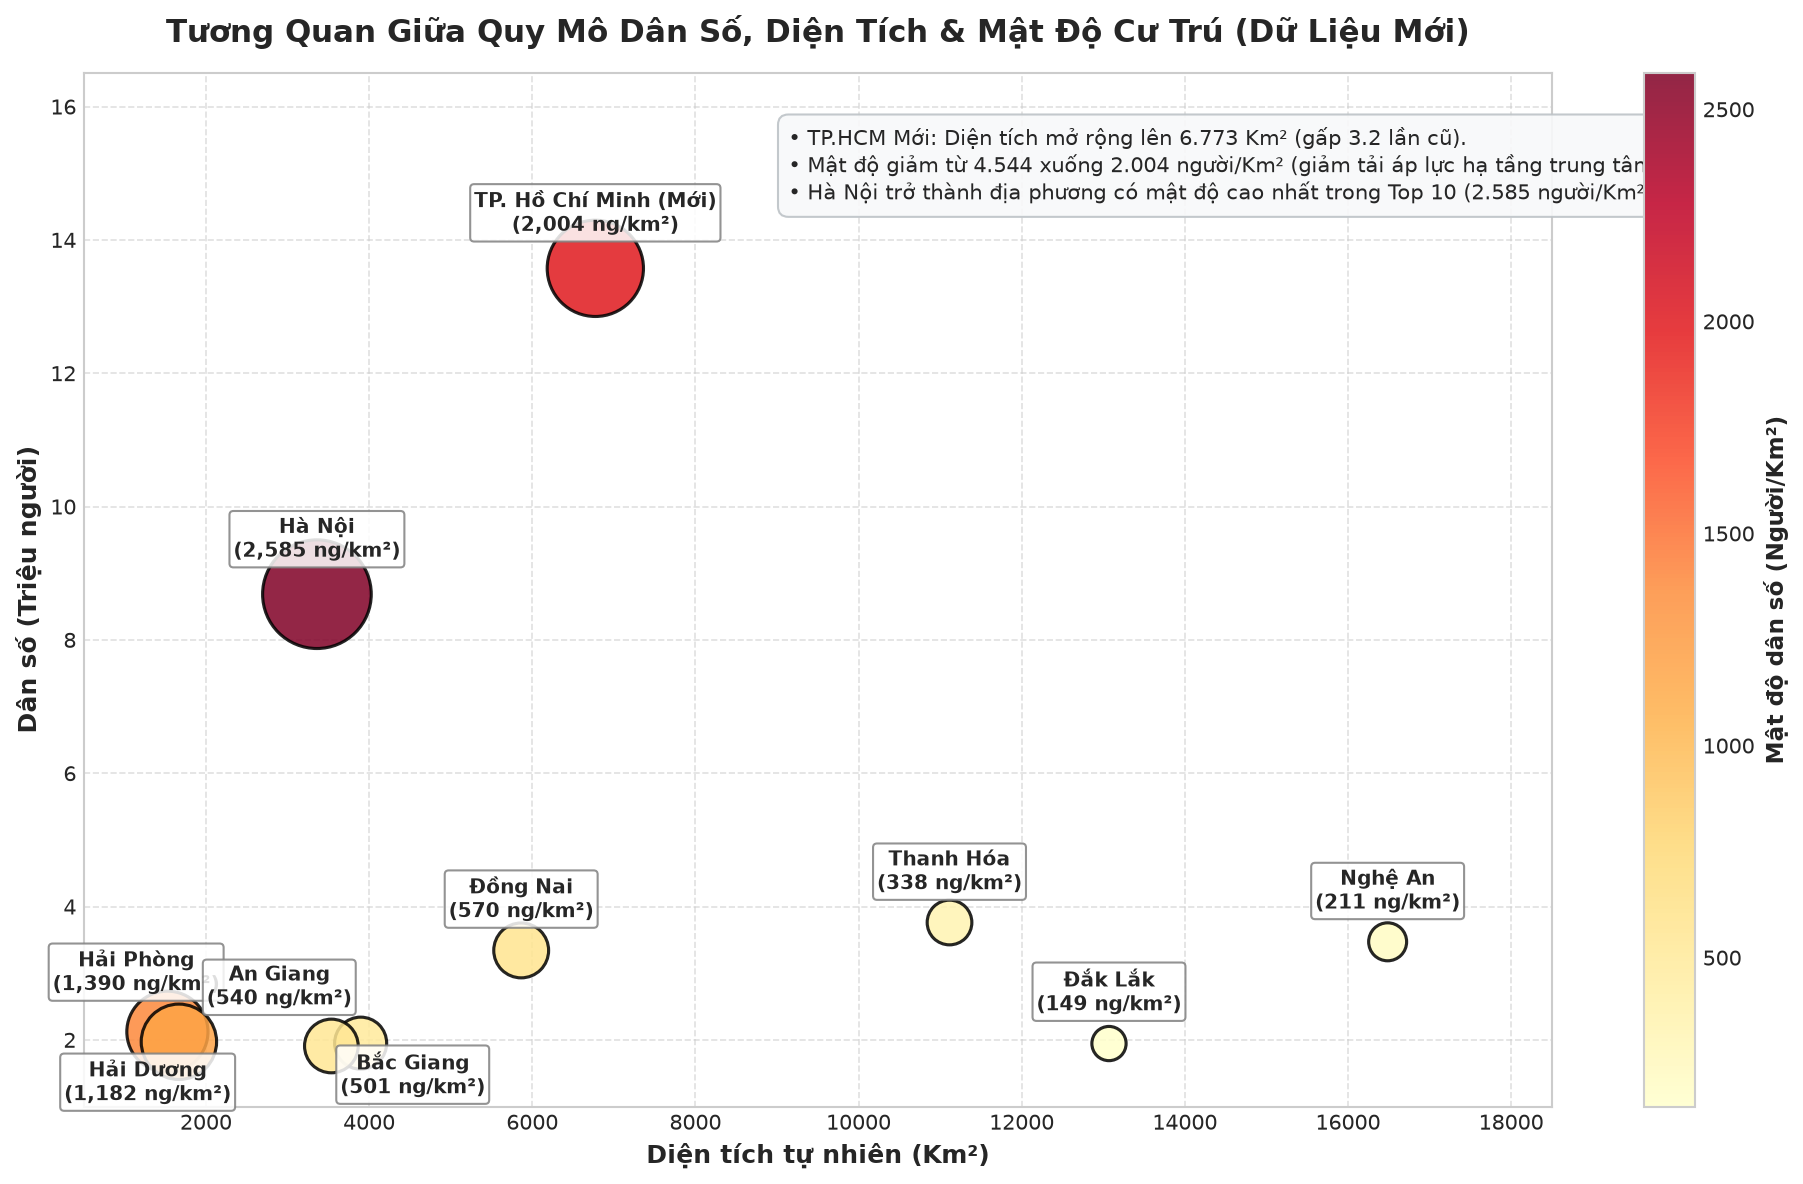

In [15]:
# 8. Tương quan Dân số, Diện tích và Mật độ dân cư theo dữ liệu mới
fig, ax = plt.subplots(figsize=(13, 8))

# Kích thước bong bóng theo mật độ
sizes = (df_top10_new['Density_per_km2'] / df_top10_new['Density_per_km2'].max()) * 2600 + 120

scatter = ax.scatter(df_top10_new['Area_km2'], df_top10_new['Population'] / 1e6, 
                     s=sizes, c=df_top10_new['Density_per_km2'], cmap='YlOrRd', 
                     edgecolors='black', alpha=0.85, linewidth=1.5)

offsets = {
    'TP. Hồ Chí Minh (Mới)': (0, 18),
    'Hà Nội': (0, 18),
    'Thanh Hóa': (0, 16),
    'Nghệ An': (0, 16),
    'Đồng Nai': (0, 16),
    'Hải Phòng': (-15, 20),
    'Hải Dương': (-15, -28),
    'Bắc Giang': (25, -24),
    'An Giang': (-25, 20),
    'Đắk Lắk': (0, 16)
}

for _, row in df_top10_new.iterrows():
    p = row['Province']
    offset = offsets.get(p, (0, 14))
    ax.annotate(f"{p}\n({row['Density_per_km2']:,} ng/km²)", 
                (row['Area_km2'], row['Population'] / 1e6),
                textcoords="offset points", xytext=offset, ha='center',
                fontsize=9.5, fontweight='bold', 
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="gray", alpha=0.85))

cbar = plt.colorbar(scatter)
cbar.set_label('Mật độ dân số (Người/Km²)', fontsize=11, fontweight='bold')

ax.set_title('Tương Quan Giữa Quy Mô Dân Số, Diện Tích & Mật Độ Cư Trú (Dữ Liệu Mới)', fontsize=15, fontweight='bold', pad=15)
ax.set_xlabel('Diện tích tự nhiên (Km²)', fontsize=12, fontweight='bold')
ax.set_ylabel('Dân số (Triệu người)', fontsize=12, fontweight='bold')
ax.set_ylim(1.0, 16.5)
ax.set_xlim(500, 18500)
ax.grid(True, linestyle='--', alpha=0.6)

# Chú giải phân tích
ax.text(0.48, 0.95, '• TP.HCM Mới: Diện tích mở rộng lên 6.773 Km² (gấp 3.2 lần cũ).\n• Mật độ giảm từ 4.544 xuống 2.004 người/Km² (giảm tải áp lực hạ tầng trung tâm).\n• Hà Nội trở thành địa phương có mật độ cao nhất trong Top 10 (2.585 người/Km²).', 
        transform=ax.transAxes, va='top', fontsize=10, 
        bbox=dict(boxstyle='round,pad=0.5', facecolor='#f8f9fa', alpha=0.9, edgecolor='#bdc3c7'))

plt.tight_layout()
plt.show()


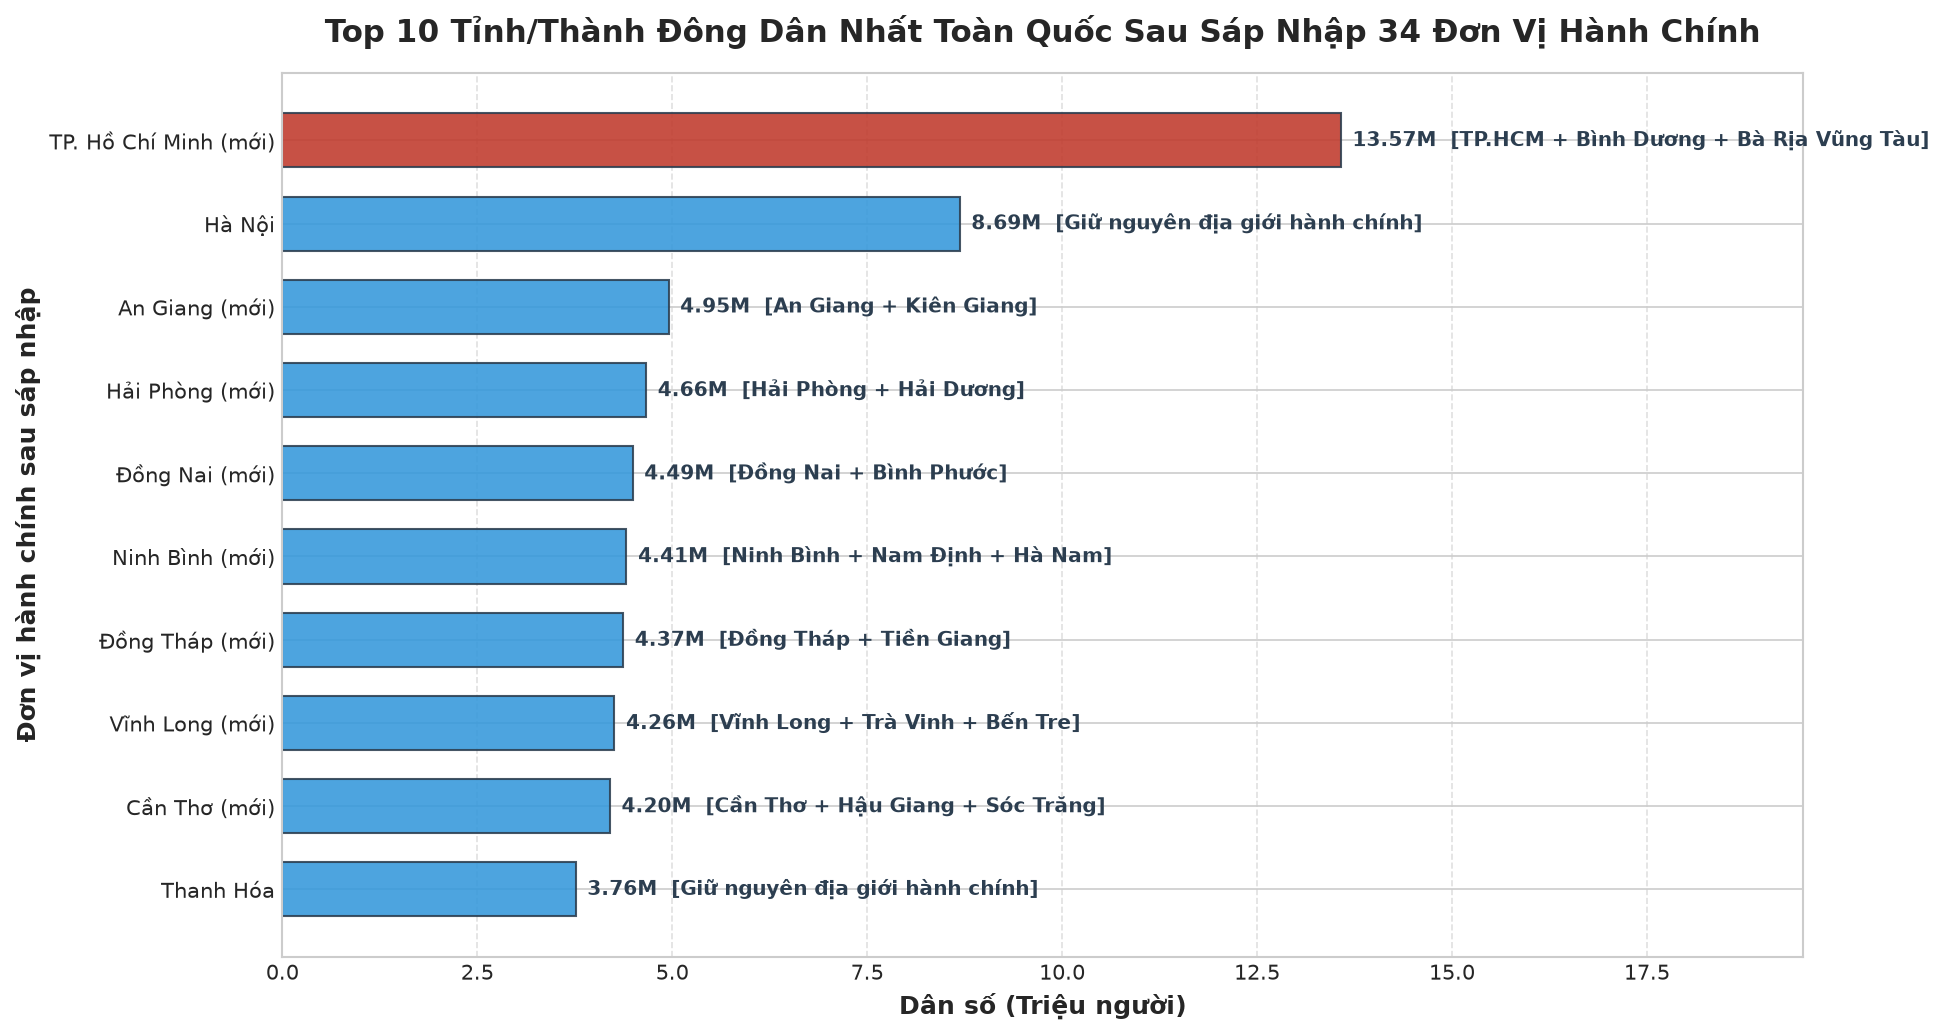

In [16]:
# 9. Mở rộng: Bảng xếp hạng Top 10 sau khi sáp nhập 34 tỉnh/thành toàn quốc
fig, ax = plt.subplots(figsize=(13, 7))

df_sorted_34 = df_top10_34.sort_values(by='Population', ascending=True).reset_index(drop=True)

colors_34 = ['#c0392b' if 'TP. Hồ Chí Minh' in p else '#3498db' for p in df_sorted_34['Province']]

bars = ax.barh(df_sorted_34['Province'], df_sorted_34['Population'] / 1e6, color=colors_34, edgecolor='#2c3e50', alpha=0.88, height=0.65)

for i, bar in enumerate(bars):
    width = bar.get_width()
    comp = df_sorted_34.loc[i, 'Composition']
    ax.text(width + 0.15, bar.get_y() + bar.get_height()/2, 
            f'{width:.2f}M  [{comp}]', 
            va='center', ha='left', fontsize=9.5, fontweight='bold', color='#2c3e50')

ax.set_title('Top 10 Tỉnh/Thành Đông Dân Nhất Toàn Quốc Sau Sáp Nhập 34 Đơn Vị Hành Chính', fontsize=15, fontweight='bold', pad=15)
ax.set_xlabel('Dân số (Triệu người)', fontsize=12, fontweight='bold')
ax.set_ylabel('Đơn vị hành chính sau sáp nhập', fontsize=12, fontweight='bold')
ax.set_xlim(0, 19.5)
ax.grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


---
## 📝 TỔNG KẾT & ĐÁNH GIÁ CHUYÊN SÂU

1. **Hiệu ứng TP. Hồ Chí Minh Mới:**
   - Việc tích hợp TP.HCM với **Bình Dương** (thủ phủ công nghiệp) và **Bà Rịa - Vũng Tàu** (cửa ngõ hàng hải cụm cảng Cái Mép) tạo ra một siêu đô thị quy mô **13,57 triệu dân**, chiếm **13,42%** dân số cả nước.
   - Không gian tự nhiên mở rộng từ 2.095 km² lên 6.773 km², giúp mật độ dân số bình quân được phân bổ từ 4.544 người/km² về mức hợp lý hơn là 2.004 người/km².

2. **Sự thay đổi trật tự Top 10 tỉnh/thành đông dân nhất:**
   - Khi Bình Dương hợp nhất vào TP.HCM, tỉnh An Giang (1,91 triệu dân) được đôn lên Top 10.
   - Thủ đô Hà Nội giữ vững vị trí số 2 (8,69 triệu người) và trở thành địa phương có mật độ cao nhất trong bảng xếp hạng mới (2.585 người/km²).
   - Top 10 tỉnh thành theo dữ liệu mới chiếm tới **43,1%** tổng dân số toàn quốc, khẳng định mức độ tập trung dân cư và nguồn nhân lực cao tại các cực kinh tế đầu tàu.
